# Segunda evaluación: variables y modelos de riesgo

**Pregunta:** ¿mejoran los resultados al añadir datos de ingreso y ajustar los cuatro modelos? **Meta:** macro-F1 > 0,80 **y** accuracy > 0,80 para las cuatro clases originales.

**Diseño:** conservamos los 3.200 proyectos de desarrollo y los 800 del test anterior. En desarrollo hacemos validación anidada: 3 folds externos para evaluar, 2 internos para elegir parámetros, modelo y conjunto de variables. Después seleccionamos la configuración final con 3 folds internos sobre todo desarrollo. El test anterior se consulta únicamente al terminar y se etiqueta como **referencia ya consultada**, no como nueva prueba independiente.

El dataset completo y el test ya informaron decisiones anteriores: esta validación anidada reduce el sesgo de la nueva búsqueda, pero no sustituye datos futuros independientes. No se conocen las fechas de medición ni la definición completa de Risk_Level.

Ejecutar junto al CSV con el kernel `.venv_modelos/Scripts/python.exe`. El módulo `_support/optimizar_riesgo.py` contiene los bucles repetidos; el notebook muestra decisiones, parámetros, comparaciones y diagnósticos. Los checkpoints permiten reanudar sin entrenar otra vez lo ya calculado.

## 1. Datos y tres conjuntos de entrada

- **A · 13 iniciales:** referencia de formulario.
- **B · 17 ingreso:** añade experiencia del responsable, madurez del control de cambios, dependencias entre áreas y competencia por recursos. Son plausibles al ingreso, todavía requieren definición y fecha de captura consistentes.
- **C · 22 condicionadas:** añade complejidad, complejidad de integración, proyectos similares, éxito de entregas previas y disponibilidad de recursos. Su uso requiere confirmar escalas, fuentes y corte temporal. Una mejora no autoriza automáticamente su uso en el formulario.

Se excluyen ID, objetivo y las variables de ejecución identificadas. N/A y None se conservan como categorías; no se inventan entradas ni se generan muestras sintéticas.

In [1]:
from pathlib import Path
import hashlib, json, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import Markdown
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from _support.optimizar_riesgo import (
    SETS, BASE, EXTRA, CONDITIONAL, MODELS, GRIDS, CLASSES,
    metrics, nested_comparison, final_search, learning_diagnostic, permutation_oof)

OUTPUT = Path('resultados_modelos_v2')
OUTPUT.mkdir(exist_ok=True)
df = pd.read_csv('project_dataset.csv', keep_default_na=False)
particiones = pd.read_csv('resultados_modelos/particiones.csv')
assert df.Project_ID.is_unique and particiones.Project_ID.is_unique
assert set(df.Project_ID) == set(particiones.Project_ID)
particion = df.Project_ID.map(particiones.set_index('Project_ID')['partición'])
assert set(particion) == {'desarrollo', 'test'}
campos = list(SETS.values())[-1]
assert not set(campos) & {'Project_ID', 'Risk_Level', 'Team_Turnover_Rate',
    'Budget_Utilization_Rate', 'Project_Phase', 'Current_Phase_Duration_Months'}
X, y = df[campos].copy(), df.Risk_Level.copy()
assert not X.isna().any().any() and not X.astype(str).eq('').any().any()
for c in X.select_dtypes(exclude='number'):
    X[c] = X[c].astype(str)
dev, ref = particion.eq('desarrollo'), particion.eq('test')
X_dev, y_dev = X.loc[dev], y.loc[dev]
X_ref, y_ref = X.loc[ref], y.loc[ref]
assert len(X_dev) == 3200 and len(X_ref) == 800
assert set(X_dev.index).isdisjoint(X_ref.index)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
display(pd.DataFrame([
    {'conjunto': name, 'campos': len(cols), 'numéricos': len(X[cols].select_dtypes('number').columns),
     'categóricos': len(X[cols].select_dtypes(exclude='number').columns),
     'nuevos campos': ', '.join(BASE if cols == BASE else EXTRA if len(cols) == 17 else CONDITIONAL)}
    for name, cols in SETS.items()
]))
print(f'Desarrollo: {len(X_dev)} | Referencia ya consultada: {len(X_ref)}')
print({p: metadata.version(p) for p in ['pandas', 'numpy', 'scikit-learn', 'catboost']})
protocolo = {'csv_sha256': hashlib.sha256(Path('project_dataset.csv').read_bytes()).hexdigest(),
    'engine_sha256': hashlib.sha256(Path('_support/optimizar_riesgo.py').read_bytes()).hexdigest(),
    'conjuntos': SETS, 'grillas': GRIDS, 'outer_folds': 3, 'inner_folds': 2,
    'criterio': 'macro-F1; desempate accuracy, recall High/Critical y menos variables',
    'test_previamente_consultado': True}
(OUTPUT / 'protocolo.json').write_text(json.dumps(protocolo, ensure_ascii=False, indent=2), encoding='utf-8')

,conjunto,campos,numéricos,categóricos,nuevos campos
0,A · 13 iniciales,13,5,8,"Project_Budget_USD, Estimated_Timeline_Months, Team_Size, Stakeholder_Count, External_Dependencies_Count, Project_Ty..."
1,B · 17 ingreso,17,6,11,"Project_Manager_Experience, Change_Control_Maturity, Cross_Functional_Dependencies, Resource_Contention_Level"
2,C · 22 condicionadas,22,11,11,"Complexity_Score, Integration_Complexity, Past_Similar_Projects, Previous_Delivery_Success_Rate, Resource_Availability"


Desarrollo: 3200 | Referencia ya consultada: 800
{'pandas': '3.0.1', 'numpy': '2.3.5', 'scikit-learn': '1.9.1', 'catboost': '1.2.10'}


## 2. Qué cambia en el entrenamiento

| Modelo | Transformación | Búsqueda |
|---|---|---|
| Logística | One-hot; numéricas estandarizadas; interacciones numéricas por pares como alternativa | 6 configuraciones: C desde 0,03 a 30; con/sin interacciones |
| Árbol | One-hot; mediana para numéricas; sin escalar | 6 configuraciones de profundidad, tamaño de hoja, poda y pesos |
| Random Forest | One-hot; mediana para numéricas; sin escalar | 6 configuraciones: 250/400 árboles, profundidad, hojas, max_features y pesos |
| CatBoost | Categorías nativas; números en escala original | 3 configuraciones: hasta 700 iteraciones, profundidades 4/6, tasa, L2 y tratamiento interno de categorías |

Todas las transformaciones se ajustan dentro del entrenamiento correspondiente. En CatBoost, la parada temprana usa **solo la validación interna** (60 iteraciones sin mejora en MultiClass). El número de árboles del refit es la mediana de los elegidos internamente; no se usa el fold externo para detener el entrenamiento.

Es una búsqueda acotada de 21 configuraciones por conjunto, no una exploración exhaustiva de todas las combinaciones. Se redujo el presupuesto inicial de CatBoost por tiempo de cómputo antes de completar la evaluación, y se aplica la misma grilla reducida a todos los folds. No añadimos variables de ejecución para alcanzar artificialmente el 80%. El tiempo mide la búsqueda y su refit; el cómputo está limitado a cuatro hilos por modelo.

In [2]:
display(pd.DataFrame([{'modelo': name, 'configuraciones por conjunto': len(grid),
                        'parámetros explorados': ', '.join(sorted({k for p in grid for k in p}))}
                      for name, grid in GRIDS.items()]))
# Los valores exactos quedan visibles en protocolo.json y en el módulo auxiliar.
resultado = nested_comparison(X_dev, y_dev, OUTPUT)
folds = resultado['folds']
resumen = folds.groupby(['grupo', 'modelo'], sort=False).agg(
    macro_f1=('macro_f1', 'mean'), desv_f1=('macro_f1', 'std'),
    accuracy=('accuracy', 'mean'), recall_alto=('recall_alto', 'mean'),
    train_f1=('train_f1', 'mean'), segundos=('seconds', 'sum')).reset_index()
resumen['brecha_train_validacion'] = resumen.train_f1 - resumen.macro_f1
resumen['supera_ambas_metas'] = resumen.macro_f1.gt(.80) & resumen.accuracy.gt(.80)
display(resumen)
resumen.to_csv(OUTPUT / 'comparacion_anidada.csv', index=False)

,modelo,configuraciones por conjunto,parámetros explorados
0,Logística,6,"C, degree"
1,Árbol,6,"ccp_alpha, class_weight, max_depth, min_samples_leaf"
2,Random Forest,6,"class_weight, max_depth, max_features, min_samples_leaf, n_estimators"
3,CatBoost,3,"depth, iterations, l2_leaf_reg, learning_rate, one_hot_max_size"


Fold 1/3 | A · 13 iniciales | Logística | F1 externo 0.543
Fold 1/3 | A · 13 iniciales | Árbol | F1 externo 0.419
Fold 1/3 | A · 13 iniciales | Random Forest | F1 externo 0.479
Fold 1/3 | A · 13 iniciales | CatBoost | F1 externo 0.546
Fold 1/3 | B · 17 ingreso | Logística | F1 externo 0.555
Fold 1/3 | B · 17 ingreso | Árbol | F1 externo 0.418
Fold 1/3 | B · 17 ingreso | Random Forest | F1 externo 0.518
Fold 1/3 | B · 17 ingreso | CatBoost | F1 externo 0.558
Fold 1/3 | C · 22 condicionadas | Logística | F1 externo 0.588
Fold 1/3 | C · 22 condicionadas | Árbol | F1 externo 0.435
Fold 1/3 | C · 22 condicionadas | Random Forest | F1 externo 0.526
Fold 1/3 | C · 22 condicionadas | CatBoost | F1 externo 0.575
Fold 2/3 | A · 13 iniciales | Logística | F1 externo 0.541
Fold 2/3 | A · 13 iniciales | Árbol | F1 externo 0.423
Fold 2/3 | A · 13 iniciales | Random Forest | F1 externo 0.480
Fold 2/3 | A · 13 iniciales | CatBoost | F1 externo 0.510
Fold 2/3 | B · 17 ingreso | Logística | F1 externo 0

,grupo,modelo,macro_f1,desv_f1,accuracy,recall_alto,train_f1,segundos,brecha_train_validacion,supera_ambas_metas
0,A · 13 iniciales,Logística,0.541,0.003,0.541,0.713,0.577,3.737,0.036,False
1,A · 13 iniciales,Árbol,0.424,0.006,0.435,0.611,0.494,2.770,0.070,False
2,A · 13 iniciales,Random Forest,0.482,0.005,0.484,0.648,0.932,40.447,0.450,False
3,A · 13 iniciales,CatBoost,0.525,0.019,0.528,0.681,0.654,44.938,0.130,False
4,B · 17 ingreso,Logística,0.559,0.007,0.558,0.732,0.606,3.602,0.046,False
5,B · 17 ingreso,Árbol,0.428,0.011,0.452,0.564,0.504,1.797,0.077,False
6,B · 17 ingreso,Random Forest,0.506,0.011,0.507,0.680,0.997,40.030,0.491,False
7,B · 17 ingreso,CatBoost,0.543,0.014,0.542,0.696,0.721,56.856,0.178,False
8,C · 22 condicionadas,Logística,0.601,0.011,0.597,0.771,0.640,3.639,0.039,False
9,C · 22 condicionadas,Árbol,0.434,0.013,0.456,0.662,0.447,1.746,0.013,False


## 3. ¿Aporta más ajustar parámetros o añadir variables?
Las celdas comparan los cuatro modelos sobre exactamente los mismos folds externos. La mejora B−A y C−B es una comparación descriptiva de conjuntos, con parámetros optimizados en cada caso: no aísla un efecto causal de una columna individual. La desviación de tres folds no es un intervalo de confianza.

La tabla «selector» evalúa el procedimiento completo: en cada fold, el conjunto, el modelo y los parámetros se eligen exclusivamente en la validación interna. Es más rigurosa que tomar el máximo de esta tabla de resultados externos.

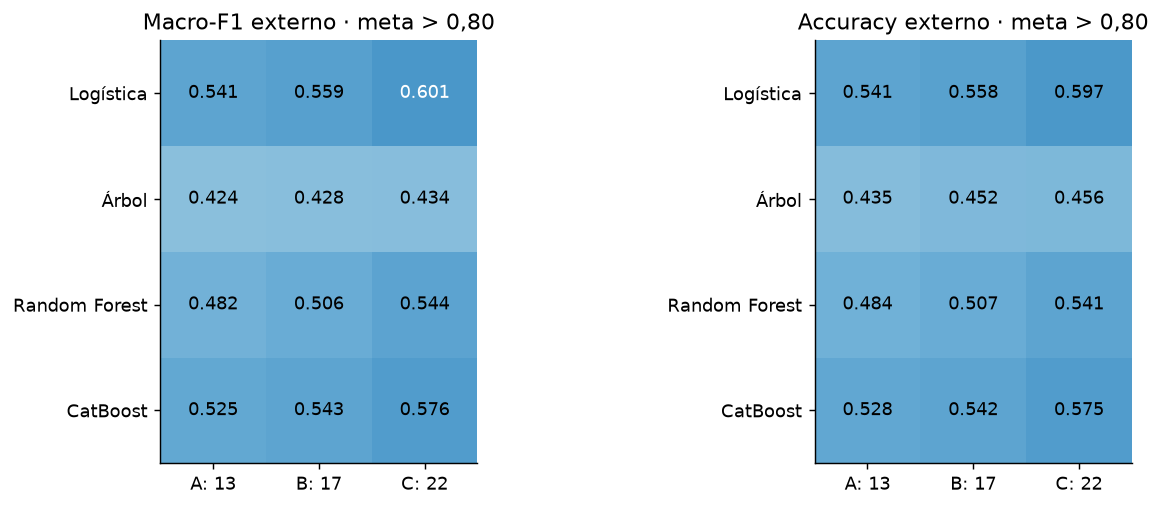

,mejora B menos A,mejora C menos B
modelo,,
CatBoost,0.018,0.033
Logística,0.019,0.042
Random Forest,0.024,0.037
Árbol,0.003,0.006


,macro_f1,accuracy,recall_alto,precision_alto,recall_critical,omitidos_alto
procedimiento,,,,,,
A · 13 iniciales,0.541,0.541,0.713,0.787,0.521,412
B · 17 ingreso,0.559,0.557,0.732,0.800,0.547,385
C · 22 condicionadas,0.601,0.597,0.771,0.815,0.599,329
Selector de conjunto + modelo + parámetros,0.601,0.597,0.771,0.815,0.599,329


,fold,grupo,modelo,macro_f1,accuracy,recall_alto,precision_alto,recall_critical,omitidos_alto
0,1,C · 22 condicionadas,Logística,0.588,0.583,0.800,0.802,0.591,96
1,2,C · 22 condicionadas,Logística,0.606,0.601,0.754,0.811,0.640,118
2,3,C · 22 condicionadas,Logística,0.609,0.607,0.760,0.833,0.567,115


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ['macro_f1', 'accuracy'], ['Macro-F1 externo', 'Accuracy externo']):
    tabla = resumen.pivot(index='modelo', columns='grupo', values=metric).reindex(index=MODELS, columns=SETS)
    ax.imshow(tabla.values, vmin=0, vmax=1, cmap='Blues')
    ax.set_xticks(range(3), ['A: 13', 'B: 17', 'C: 22'])
    ax.set_yticks(range(4), MODELS)
    ax.set_title(title + ' · meta > 0,80')
    for i in range(4):
        for j in range(3):
            val = tabla.iloc[i, j]
            ax.text(j, i, f'{val:.3f}', ha='center', va='center', color='white' if val > .6 else 'black')
fig.tight_layout()
plt.show()

f1_por_grupo = resumen.pivot(index='modelo', columns='grupo', values='macro_f1')
grupos = list(SETS)
display(pd.DataFrame({'mejora B menos A': f1_por_grupo[grupos[1]]-f1_por_grupo[grupos[0]],
                      'mejora C menos B': f1_por_grupo[grupos[2]]-f1_por_grupo[grupos[1]]}))
selectores = pd.DataFrame([
    {'procedimiento': group, **metrics(y_dev, pred)}
    for group, pred in resultado['group_oof'].items()
] + [{'procedimiento': 'Selector de conjunto + modelo + parámetros',
       **metrics(y_dev, resultado['selector_oof'])}]).set_index('procedimiento')
display(selectores)
display(resultado['selections'])
selectores.to_csv(OUTPUT / 'selectores_anidados.csv')
resultado['selections'].to_csv(OUTPUT / 'seleccion_por_fold.csv', index=False)
pd.DataFrame({'Project_ID': df.loc[dev, 'Project_ID'], 'real': y_dev,
              'prediccion_selector': resultado['selector_oof']}).to_csv(
    OUTPUT / 'predicciones_fuera_muestra.csv', index=False)

## 4. Selección final y referencia de 800 proyectos
Volvemos a buscar dentro de los 3.200 de desarrollo con 3 folds internos. Esta búsqueda, no el test ni el máximo externo, fija la configuración final. Para comparar las entradas, guardamos el mejor modelo interno de cada conjunto.

Los resultados de los 800 proyectos son **descriptivos y ya consultados en la primera ronda**. No se cambian parámetros al verlos. También se muestran los valores del experimento anterior para medir el cambio sobre las mismas filas. El conjunto C continúa condicionado a validar los cinco campos adicionales.

In [4]:
ranking_final, modelos_finales, elegido = final_search(X_dev, y_dev, OUTPUT)
display(ranking_final[['grupo', 'modelo', 'inner_f1', 'inner_accuracy', 'inner_recall', 'params']])
ranking_final.to_csv(OUTPUT / 'seleccion_final_interna.csv', index=False)
grupo_elegido, modelo_elegido = elegido
display(Markdown(f'**Configuración seleccionada internamente: {grupo_elegido} + {modelo_elegido}.**'))

referencia_filas, pred_referencia = [], {}
for group in SETS:
    row = ranking_final.loc[ranking_final.grupo.eq(group)].iloc[0]
    key = (group, row['modelo'])
    model = modelos_finales[key]['model']
    pred = np.asarray(model.predict(X_ref[SETS[group]])).ravel()
    pred_referencia[key] = pred
    referencia_filas.append({'grupo': group, 'modelo': key[1], **metrics(y_ref, pred),
                            'elegido': key == elegido})
referencia = pd.DataFrame(referencia_filas)
display(referencia)
referencia.to_csv(OUTPUT / 'referencia_previamente_consultada.csv', index=False)
anterior = pd.read_csv('resultados_modelos/comparacion_test.csv').iloc[0]
nuevo = referencia.loc[referencia.elegido].iloc[0]
display(pd.DataFrame([
    {'experimento': 'Anterior: logística con 13 campos', 'macro_f1': anterior['F1 macro'], 'accuracy': anterior['accuracy']},
    {'experimento': 'Nuevo: selección interna', 'macro_f1': nuevo.macro_f1, 'accuracy': nuevo.accuracy}
]))
seleccionado = modelos_finales[elegido]
joblib.dump({'model': seleccionado['model'], 'features': SETS[grupo_elegido],
             'group': grupo_elegido, 'name': modelo_elegido, 'params': seleccionado['params'],
             'campos_condicionados': [c for c in SETS[grupo_elegido] if c in CONDITIONAL],
             'requiere_validacion_dia_1': True}, OUTPUT / 'modelo_candidato.joblib', compress=3)

Selección final | A · 13 iniciales | Logística | F1 interno 0.545
Selección final | A · 13 iniciales | Árbol | F1 interno 0.430
Selección final | A · 13 iniciales | Random Forest | F1 interno 0.496
Selección final | A · 13 iniciales | CatBoost | F1 interno 0.520
Selección final | B · 17 ingreso | Logística | F1 interno 0.565
Selección final | B · 17 ingreso | Árbol | F1 interno 0.434
Selección final | B · 17 ingreso | Random Forest | F1 interno 0.516
Selección final | B · 17 ingreso | CatBoost | F1 interno 0.545
Selección final | C · 22 condicionadas | Logística | F1 interno 0.593
Selección final | C · 22 condicionadas | Árbol | F1 interno 0.452
Selección final | C · 22 condicionadas | Random Forest | F1 interno 0.532
Selección final | C · 22 condicionadas | CatBoost | F1 interno 0.577


,grupo,modelo,inner_f1,inner_accuracy,inner_recall,params
8,C · 22 condicionadas,Logística,0.593,0.590,0.744,"{""C"": 0.3, ""degree"": 1}"
11,C · 22 condicionadas,CatBoost,0.577,0.575,0.716,"{""iterations"": 685, ""depth"": 4, ""learning_rate"": 0.05, ""l2_leaf_reg"": 5, ""one_hot_max_size"": 10}"
4,B · 17 ingreso,Logística,0.565,0.562,0.716,"{""C"": 3, ""degree"": 2}"
7,B · 17 ingreso,CatBoost,0.545,0.545,0.701,"{""iterations"": 559, ""depth"": 4, ""learning_rate"": 0.05, ""l2_leaf_reg"": 5, ""one_hot_max_size"": 10}"
0,A · 13 iniciales,Logística,0.545,0.543,0.704,"{""C"": 3, ""degree"": 2}"
10,C · 22 condicionadas,Random Forest,0.532,0.536,0.676,"{""n_estimators"": 400, ""max_depth"": null, ""min_samples_leaf"": 1, ""max_features"": 0.5}"
3,A · 13 iniciales,CatBoost,0.520,0.523,0.678,"{""iterations"": 453, ""depth"": 4, ""learning_rate"": 0.05, ""l2_leaf_reg"": 5, ""one_hot_max_size"": 10}"
6,B · 17 ingreso,Random Forest,0.516,0.515,0.697,"{""n_estimators"": 400, ""max_depth"": null, ""min_samples_leaf"": 2, ""max_features"": ""sqrt"", ""class_weight"": ""balanced_su..."
2,A · 13 iniciales,Random Forest,0.496,0.494,0.693,"{""n_estimators"": 400, ""max_depth"": null, ""min_samples_leaf"": 2, ""max_features"": ""sqrt"", ""class_weight"": ""balanced_su..."
9,C · 22 condicionadas,Árbol,0.452,0.445,0.764,"{""max_depth"": 8, ""min_samples_leaf"": 10, ""ccp_alpha"": 0, ""class_weight"": ""balanced""}"


**Configuración seleccionada internamente: C · 22 condicionadas + Logística.**

,grupo,modelo,macro_f1,accuracy,recall_alto,precision_alto,recall_critical,omitidos_alto,elegido
0,A · 13 iniciales,Logística,0.519,0.520,0.706,0.796,0.536,106,False
1,B · 17 ingreso,Logística,0.544,0.537,0.694,0.799,0.614,110,False
2,C · 22 condicionadas,Logística,0.590,0.581,0.753,0.816,0.667,89,True


,experimento,macro_f1,accuracy
0,Anterior: logística con 13 campos,0.518,0.519
1,Nuevo: selección interna,0.590,0.581


## 5. Diagnóstico de aprendizaje y variables
La curva usa la configuración final fija y tres particiones de desarrollo con 35%, 65% y 100% del entrenamiento de cada fold. Es **descriptiva**: esos datos también participaron en su selección. Brecha grande entre entrenamiento y validación sugiere sobreajuste; ambos bajos sugieren información o capacidad insuficientes, sin probar cuál es la causa.

La importancia por permutación desordena cada columna original en los folds externos y mide la caída de macro-F1 de sus predicciones fuera de muestra (3 repeticiones). Es exploratoria: la combinación examinada fue elegida con desarrollo. Variables redundantes pueden compartir importancia; no indica causalidad ni autoriza captar un dato posterior.

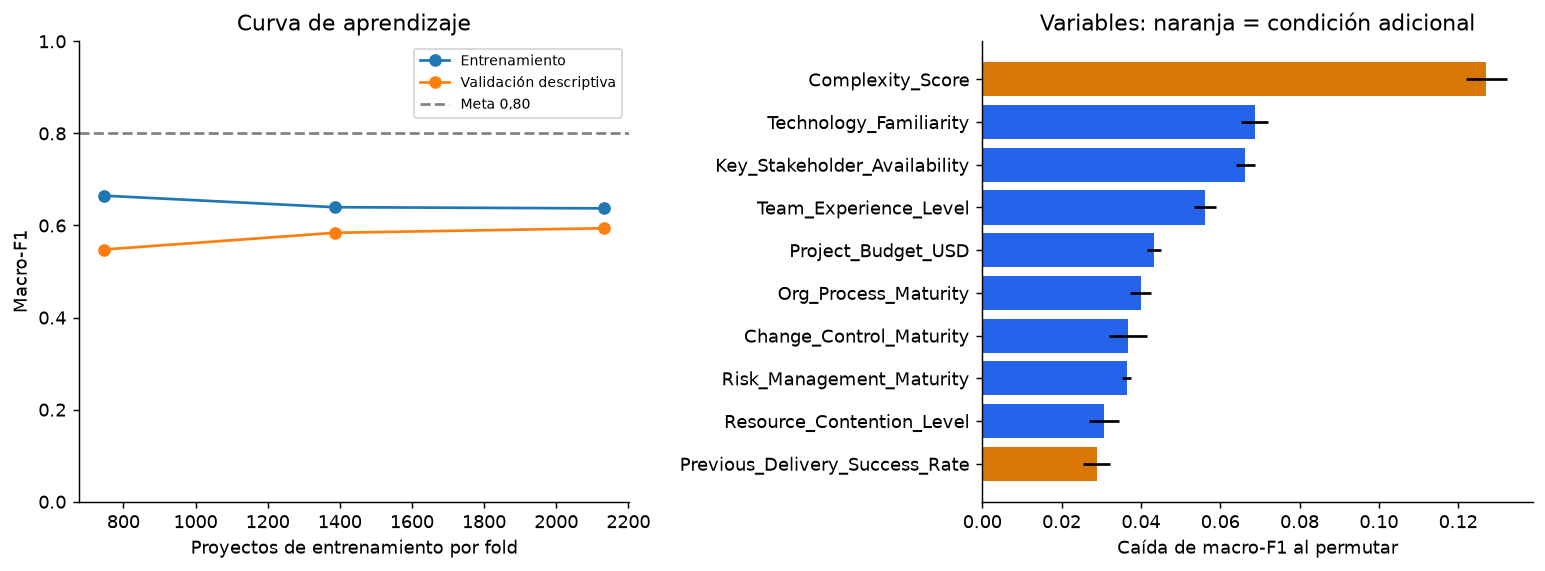

,variable,caida_f1,desv_repeticiones,requiere_validacion_adicional
17,Complexity_Score,0.127,0.005,True
7,Technology_Familiarity,0.069,0.003,False
10,Key_Stakeholder_Availability,0.066,0.002,False
6,Team_Experience_Level,0.056,0.003,False
0,Project_Budget_USD,0.043,0.002,False
11,Org_Process_Maturity,0.040,0.003,False
14,Change_Control_Maturity,0.037,0.005,False
12,Risk_Management_Maturity,0.036,0.001,False
16,Resource_Contention_Level,0.031,0.004,False
20,Previous_Delivery_Success_Rate,0.029,0.004,True


,n_train,train,validacion
fraction,,,
0.350,746.000,0.665,0.548
0.650,1386.333,0.640,0.584
1.000,2133.333,0.637,0.594


In [5]:
curva = learning_diagnostic(X_dev, y_dev, grupo_elegido, modelo_elegido, seleccionado)
importancia = permutation_oof(X_dev, y_dev, resultado, grupo_elegido, modelo_elegido)
curva.to_csv(OUTPUT / 'curva_aprendizaje.csv', index=False)
importancia.to_csv(OUTPUT / 'importancia_variables.csv', index=False)
curva_media = curva.groupby('fraction').agg(n_train=('n_train', 'mean'),
    train=('train_f1', 'mean'), validacion=('validation_f1', 'mean'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(curva_media.n_train, curva_media.train, 'o-', label='Entrenamiento')
axes[0].plot(curva_media.n_train, curva_media.validacion, 'o-', label='Validación descriptiva')
axes[0].axhline(.80, color='gray', linestyle='--', label='Meta 0,80')
axes[0].set(xlabel='Proyectos de entrenamiento por fold', ylabel='Macro-F1',
            ylim=(0, 1), title='Curva de aprendizaje')
axes[0].legend(fontsize=8)
top = importancia.head(10).iloc[::-1]
axes[1].barh(top.variable, top.caida_f1, xerr=top.desv_repeticiones,
             color=['#d97706' if c else '#2563eb' for c in top.requiere_validacion_adicional])
axes[1].set(xlabel='Caída de macro-F1 al permutar',
            title='Variables: naranja = condición adicional')
fig.tight_layout()
plt.show()
display(importancia)
display(curva_media)

## 6. Errores y decisión frente a la meta
La matriz izquierda corresponde a la selección completa fuera de muestra en desarrollo; la derecha, al candidato final en la referencia ya consultada. Pueden corresponder a configuraciones diferentes. Agrupar High/Critical es una métrica operativa complementaria: **la meta sigue siendo de cuatro clases**, no una tarea binaria más fácil.

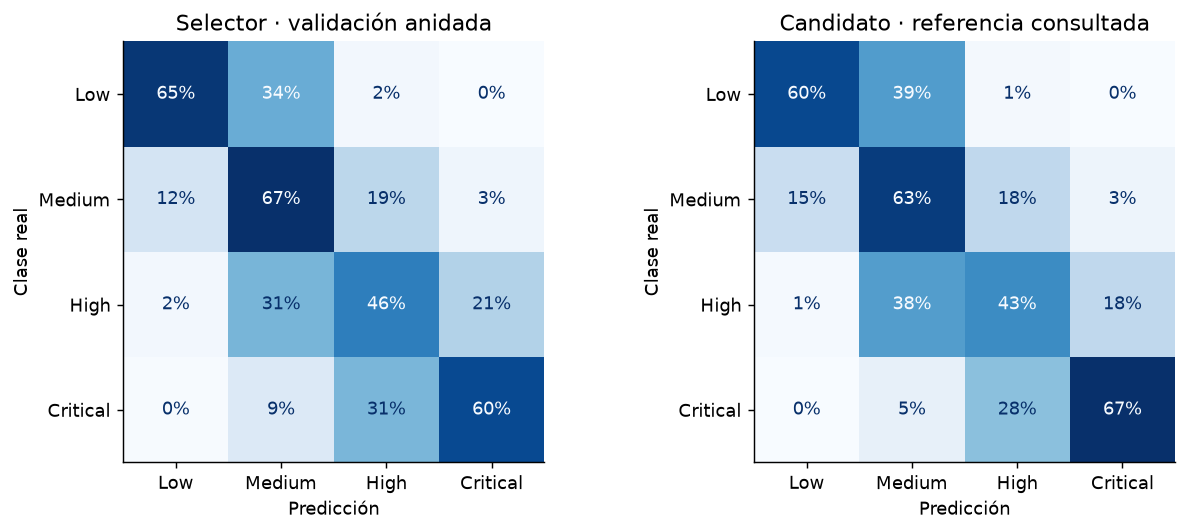

,precision,recall,f1-score,support
Low,0.683,0.602,0.640,161.000
Medium,0.543,0.634,0.585,279.000
High,0.484,0.430,0.455,207.000
Critical,0.689,0.667,0.678,153.000
accuracy,0.581,0.581,0.581,0.581
macro avg,0.600,0.583,0.590,800.000
weighted avg,0.584,0.581,0.580,800.000


**Meta en validación anidada: no alcanzada.** Macro-F1 0.601; accuracy 0.597. La referencia consultada obtiene macro-F1 0.590 y accuracy 0.581. El candidato seleccionado es **Logística, 22 campos**. Requiere confirmar estos campos adicionales: Complexity_Score, Integration_Complexity, Past_Similar_Projects, Previous_Delivery_Success_Rate, Resource_Availability. No se garantiza el riesgo de un caso individual. Antes de automatizar la atención, validar el momento de captura, la definición de Risk_Level y las probabilidades en datos nuevos. No se calibraron probabilidades en esta ronda.

Verificados: 12 combinaciones, 3 folds externos, predicciones completas y modelo guardado reproducible.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, real, pred, title in [
    (axes[0], y_dev, resultado['selector_oof'], 'Selector · validación anidada'),
    (axes[1], y_ref, pred_referencia[elegido], 'Candidato · referencia consultada')]:
    ConfusionMatrixDisplay.from_predictions(real, pred, labels=CLASSES, normalize='true',
        cmap='Blues', colorbar=False, values_format='.0%', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Clase real')
fig.tight_layout()
plt.show()
display(pd.DataFrame(classification_report(y_ref, pred_referencia[elegido],
    labels=CLASSES, output_dict=True, zero_division=0)).T)

global_nested = metrics(y_dev, resultado['selector_oof'])
global_ref = metrics(y_ref, pred_referencia[elegido])
cumple_nested = global_nested['macro_f1'] > .80 and global_nested['accuracy'] > .80
cumple_ref = global_ref['macro_f1'] > .80 and global_ref['accuracy'] > .80
condicionados = [c for c in SETS[grupo_elegido] if c in CONDITIONAL]
texto = (f'**Meta en validación anidada: {"alcanzada" if cumple_nested else "no alcanzada"}.** '
    f'Macro-F1 {global_nested["macro_f1"]:.3f}; accuracy {global_nested["accuracy"]:.3f}. '
    f'La referencia consultada obtiene macro-F1 {global_ref["macro_f1"]:.3f} '
    f'y accuracy {global_ref["accuracy"]:.3f}. '
    f'El candidato seleccionado es **{modelo_elegido}, {len(SETS[grupo_elegido])} campos**. '
    + ('Requiere confirmar estos campos adicionales: ' + ', '.join(condicionados) + '. ' if condicionados else '')
    + 'No se garantiza el riesgo de un caso individual. Antes de automatizar la atención, validar el momento de captura, '
      'la definición de Risk_Level y las probabilidades en datos nuevos. No se calibraron probabilidades en esta ronda.')
display(Markdown(texto))
conclusion = {'seleccion': {'grupo': grupo_elegido, 'modelo': modelo_elegido,
                          'variables': SETS[grupo_elegido], 'params': seleccionado['params']},
              'validacion_selector': global_nested, 'referencia_consultada': global_ref,
              'meta_anidada': bool(cumple_nested), 'meta_referencia': bool(cumple_ref),
              'campos_condicionados': condicionados, 'texto': texto}
(OUTPUT / 'conclusion.json').write_text(json.dumps(conclusion, ensure_ascii=False, indent=2), encoding='utf-8')

# Verificaciones sobre resultados, trazabilidad y modelo guardado.
assert len(folds) == 36 and len(resumen) == 12
assert len(ranking_final) == 12
assert len(resultado['selector_oof']) == len(y_dev)
restaurado = joblib.load(OUTPUT / 'modelo_candidato.joblib')
np.testing.assert_array_equal(np.asarray(restaurado['model'].predict(X_ref[restaurado['features']])).ravel(),
                              pred_referencia[elegido])
print('Verificados: 12 combinaciones, 3 folds externos, predicciones completas y modelo guardado reproducible.')

**Cómo leer la entrega:** la comparación anidada evalúa la nueva búsqueda; la referencia de 800 filas muestra el cambio sobre datos ya vistos. Las tablas y gráficos distinguen rendimiento, complejidad y condiciones de captura. No se modificó el objetivo ni se incluyeron variables de ejecución para satisfacer la meta.

Referencias: [validación anidada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [ajuste de CatBoost](https://catboost.ai/docs/en/concepts/parameter-tuning), [importancia por permutación](https://scikit-learn.org/stable/modules/permutation_importance.html).

Rastro de IA: se amplió la propuesta inicial de 13 campos, se implementaron búsquedas acotadas y se corrigió la interpretación del test previamente consultado. Las métricas provienen de ejecuciones reales. El modelo guardado es un candidato experimental, no un sistema validado en producción.